# Lesson 12: CSV to `geoDataFrame` + Streamline your code

Before class, make sure you can import the data we will use in [lesson 12](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html). Run the three code cells in this notebook. If they all run without errors, you are ready for class!

By the end of lesson 12, you will be able to:

- create a `geopandas.GeoDataFrame` from a CSV with longitude and latitude columns
- format printed output using f-strings
- use `for` loops, alone and with `zip()`, to avoid repeating code
- check that your code does what you expect using `assert`
- create figures with multiple axes
- write functions with docstrings to reuse code

## About the data

We will use two datasets:

1. **Power plants**: a CSV with the operable electric generating plants in the United States by energy source, as of February 2025, from the U.S. Energy Information Administration (EIA). We will read it directly from its URL, so you don't need to download it. See the [dataset's page and metadata](https://hub.arcgis.com/datasets/fedmaps::power-plants-in-the-u-s--2/about).

2. **US states**: the 2026 TIGER shapefile of the US states from the United States Census Bureau. See the [TIGER/Line shapefiles page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) and the [technical documentation](https://www2.census.gov/geo/pdfs/maps-data/data/tiger/tgrshp2026/TGRSHP2026_TechDoc.pdf) for the metadata. To download it:
    1. At the [2026 TIGER page](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html), under Download, click on "Web Interface".
    2. For year, select 2026, and for layer type select "States (and equivalent)". Click submit.
    3. Click on "Download national file".
    4. Unzip the file and move the `tl_2026_us_state` folder into a `data/` folder at the same level as this notebook.

Read the information about both datasets in the [lesson](https://meds-eds-220.github.io/MEDS-eds-220-course/book/chapters/lesson-11-csv-to-geodataframe/lesson-11-csv-to-geo.html) before class.

## Import libraries

In [15]:
import os

import pandas as pd
from pandas.api.types import is_string_dtype, is_numeric_dtype
import geopandas as gpd
import matplotlib.pyplot as plt


# Display all columns when looking at dataframes
pd.set_option("display.max_columns", None)

## Import power plants data

In [2]:
URL = 'https://raw.githubusercontent.com/carmengg/eds-220-book/refs/heads/main/data/power_plants_epsg4269.csv'
power_plants = pd.read_csv(URL)

power_plants.head(3)

,objectid,plant_code,plant_name,utility_id,utility_name,sector_name,street_address,city,county,state,zip,primsource,source_desc,tech_desc,install_mw,total_mw,bat_mw,bio_mw,coal_mw,geo_mw,hydro_mw,hydrops_mw,ng_mw,nuclear_mw,crude_mw,solar_mw,wind_mw,other_mw,source,period,longitude,latitude
0,62897,1873,Tower,20910,Wolverine Power Supply Coop,Electric Utility,9663 Cooperative Road,Tower,Cheboygan,Michigan,49792,petroleum,Petroleum = 19.3 MW,Petroleum Liquids,21.3,19.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,19.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-84.294970,45.362818
1,62898,1874,Caro,18895,Thumb Electric Coop of Mich,Electric Utility,2437 East Dayton Road,Caro,Tuscola,Michigan,48723,petroleum,Petroleum = 8.5 MW,Petroleum Liquids,9.4,8.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,8.5,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-83.327806,43.465899
2,62899,1875,Ubly,18895,Thumb Electric Coop of Mich,Electric Utility,4159 Ubly Road,Ubly,Huron,Michigan,48475,petroleum,Petroleum = 12.3 MW,Petroleum Liquids,12.4,12.3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,12.3,0.0,0.0,0.0,"EIA-860, EIA-860M and EIA-923",202502,-82.938806,43.721699


## Import US states shapefile

In [16]:
fp = os.path.join('data', 'tl_2026_us_state', 'tl_2026_us_state.shp')
states = gpd.read_file(fp)

states.head(3)

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,1,2,36,01779796,36,0400000US36,NY,New York,00,G4000,A,122049230845,19256680224,+42.9133974,-075.5962723,"MULTIPOLYGON (((-74.04075 40.70017, -74.04073 ..."
1,4,8,32,01779793,32,0400000US32,NV,Nevada,00,G4000,A,284537080522,1839846018,+39.3310928,-116.6151469,"POLYGON ((-119.32418 41.99392, -119.32362 41.9..."
2,4,9,02,01785533,02,0400000US02,AK,Alaska,00,G4000,A,1479942808337,244276695297,+63.3469818,-152.8385657,"MULTIPOLYGON (((-167.55823 60.22436, -167.5567..."


## CSV to `geopandas.GeoDataFrame`



In [4]:
# Create points from latitude and longitude
points = gpd.points_from_xy(power_plants['longitude'],
                            power_plants['latitude'])

# Create geodataframe
power_plants = gpd.GeoDataFrame(power_plants,       # data
                                geometry=points,    # specify geometry column
                                crs='EPSG:4269')    # specify CRS

In [5]:
power_plants.geometry

0         POINT (-84.29497 45.36282)
1          POINT (-83.32781 43.4659)
2          POINT (-82.93881 43.7217)
3            POINT (-85.426 43.8393)
4            POINT (-85.8551 42.731)
                    ...             
13440        POINT (-118.109 34.608)
13441     POINT (-79.28172 42.50275)
13442     POINT (-77.74272 43.18914)
13443     POINT (-75.90345 42.33782)
13444    POINT (-120.63443 37.08391)
Name: geometry, Length: 13445, dtype: geometry

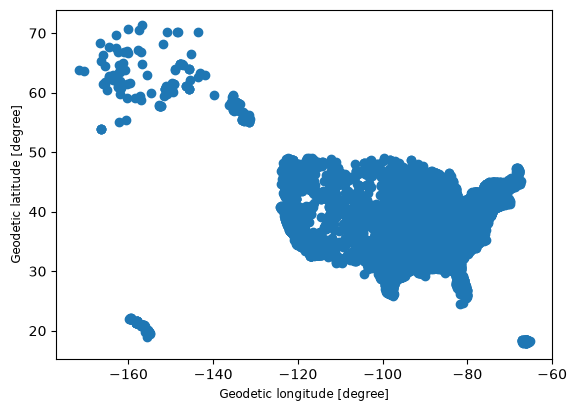

In [6]:
power_plants.plot()
plt.show()

## f-strings

In [7]:
print('CRS:',power_plants.crs)

CRS: EPSG:4269


In [8]:
# explore CRS
print(f"Ellipsoid: {power_plants.crs.ellipsoid}")
print(f"datum: {power_plants.crs.datum}")

Ellipsoid: GRS 1980
datum: North American Datum 1983


In [9]:
# :, adds thousands separators
print(f"The data has {len(power_plants):,} power plants in {power_plants['state'].nunique()} states and territories.")

# :.2f rounds to 2 decimals
print(f"Average installed capacity: {power_plants['install_mw'].mean():.2f} MW")

The data has 13,445 power plants in 52 states and territories.
Average installed capacity: 99.39 MW


## shapefile

EPSG:4269


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

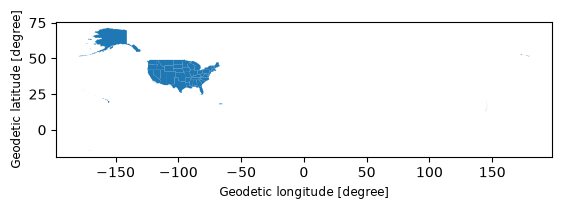

In [10]:
print(states.crs)
states.plot()

## `for` loops

In [18]:
states.columns

states.columns = states.columns.str.lower()


In [12]:
code_cols = ['region','division','statefp']

# Check whether codes columns are strings
for column in code_cols:
    print(f"{column} is string dtype? {is_string_dtype(states[column])}")

region is string dtype? True
division is string dtype? True
statefp is string dtype? True


## `assert`

In [13]:
# Update code columns into integers
for column in code_cols:
    states[column] = states[column].astype('int')
    assert is_numeric_dtype(states[column])

In [14]:
# Does nothing if statement is True
assert 2+2 == 4

# Raises an error if statement is False
assert 2+2 == 3

AssertionError: 

## Data Selection

In [22]:
# unique values for region, division, or state codes
for column in code_cols:
    print(f"{column} has {states[column].nunique()} values.")

# Select contiguous US states
contiguous = states[(states['region']!=9) & (~states['statefp'].isin([2,15]))]

region has 5 values.
division has 10 values.
statefp has 56 values.


In [23]:
# Check in
power_plants = power_plants[~power_plants['state'].isin(['Puerto Rico','Hawaii','Alaska'])]

## Plotting

In [ ]:
assert contiguous.crs == power_plants.crs

In [ ]:
fig, ax = plt.subplots(figsize = (9,5))

# Remove the axis for a cleaner map
ax.axis("off")

# Title for the plot
ax.set_title('Operable electric generating plants in the contiguous United States', fontsize=15)

# Add states
contiguous.plot(ax=ax,
                color='none',
                edgecolor='#362312')

# Add electric power plants colored by energy source
power_plants.plot(ax=ax,
                  column='primsource',
                  legend=True,
                  markersize=4,
                  cmap='tab20',
                  alpha=0.5,
                  legend_kwds={
                      'title':'Primary energy source',
                      'title_fontsize':'small',
                      'fontsize':'small',
                      'loc':'upper left',
                      'bbox_to_anchor': (0,0),
                      'ncols': 6
                  })
plt.show()

## `for` with `zip`

In [ ]:
# Interate over a single list
numbers = [1,2,3]
for num in numbers:
    print(num)
print('\n')

# Iterate over two lists in pairs using zip()
letters = ['a','b','c']
for num, letter in zip(numbers, letters):
    print(num, letter)

In [ ]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7,3))

axes[0].set_title('This is axis 0.')
axes[1].set_title('This is axis 1.')
axes[2].set_title('This is axis 2.')

plt.show()

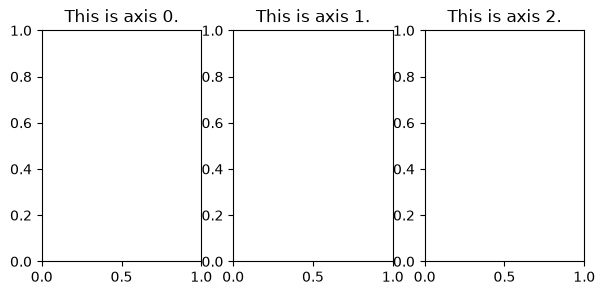

In [25]:
# Check in

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(7,3))

for ax, i in zip(axes, range(0,3)):
    ax.set_title(f'This is axis {i}.')

Text(0.5, 0.98, 'Top 3 energy sources for electric power plants in CA')

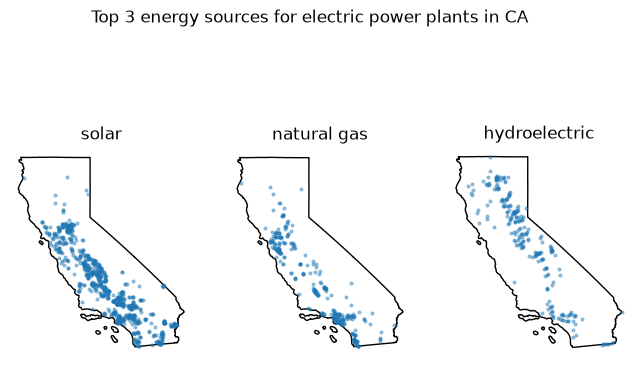

In [29]:
ca_power_plants = power_plants[power_plants['state'] == 'California']
ca_top_sources = ca_power_plants['primsource'].value_counts().index[:3].tolist()
ca_boundary = states[states['name'] == 'California']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8,5))

for ax, source in zip(axes, ca_top_sources):
    ax.set_title(source)
    ax.axis('off')
    ca_boundary.plot(ax=ax,
                     color = 'none',
                     edgecolor = 'black')
    ca_power_plants[ca_power_plants['primsource'] == source].plot(ax=ax,
                                                                  markersize = 4,
                                                                  alpha = 0.4)

fig.suptitle('Top 3 energy sources for electric power plants in CA')

## Functions

In [ ]:
def greet():
    """Print a greeting message."""
    print("Hello, welcome to the class!")

In [ ]:
def calculate_area(radius):
    """
    Calculate the area of a circle given its radius.

    Args:
        radius (float): The radius of the circle.

    Returns:
        float: The area of the circle, calculated as π * radius^2.
    """
    area = 3.14159 * radius ** 2
    return area

In [ ]:
def top3_sources(state, plants):
    """
    Find the top 3 electric primary sources of a given state.

    Args:
        state (str): The US state we want information about.
        plants (pd.DataFrame): DataFrame containing data
        on power plants, with at least 'state' and 'primsource' columns.

    Returns:
        list: A list of the top 3 primary sources of the state within the plants data frame.
    """
    state_plants = plants[plants['state']==state]
    return (state_plants['primsource']
            .value_counts()
            .index[:3]
            .tolist()
            )

In [ ]:
print('Top 3 primary energy sources in Division 2 states:')
for state in ['New Jersey', 'New York', 'Pennsylvania']:
    print(f"{state}: {top3_sources(state, power_plants)}")

In [ ]:
def plot_3_energy_sources(state, sources, plants, boundaries):
    """
    Plot the power plants of a given state for three primary energy sources.

    Args:
        state (str): The US state we want to plot.
        sources (list): A list of three primary energy sources.
        plants (gpd.GeoDataFrame): GeoDataFrame containing data
        on power plants, with at least 'state' and 'primsource' columns.
        boundaries (gpd.GeoDataFrame): GeoDataFrame with the US states boundaries,
        with at least a 'name' column.
    """
    # Raise error if sources does not have exactly three elements
    assert len(sources) == 3, 'sources must have three elements to produce the plot'

    # Isolate the state boundary and power plants
    boundary = boundaries[boundaries['name']==state]
    state_power_plants = plants[plants['state']==state]

    # Create plot
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(6, 3))

    for ax, source in zip(axes, sources):
        boundary.plot(ax=ax,                
                      color='none',
                      edgecolor='#362312')
        subset = state_power_plants[state_power_plants['primsource'] == source]
        subset.plot(ax=ax, markersize=5, alpha=0.5)
        ax.set_title(source)
        ax.axis('off')  # Remove axes for a cleaner look

    plt.suptitle(f"Top 3 energy sources for electric power plants in {state}")
    plt.tight_layout()
    plt.show()

In [ ]:
plot_3_energy_sources('New Jersey', 
                         top3_sources('New Jersey', power_plants),
                         power_plants,
                         states)

In [ ]:
# Exercise 1
def states_with_source(primsource):
    """
    list of states that have power plants with that primary source
    """
    source = power_plants[power_plants['primsource'] == primsource]
    return source['state'].unique()


In [ ]:
states_with_source('solar')

In [ ]:
# Exercise 2

def power_source_counts(primsource):
    """
    given a power source, returns a Series with counts of power plants by state that use that source
    """
    source = power_plants[power_plants['primsource'] == primsource]

    return source['state'].value_counts()
    

In [ ]:
# Exercise 3

def plot_source(primsource):
    """
    Produces a plot of the top three states for any given power source
    """
    source = power_plants[power_plants['primsource'] == primsource]
    top_3_states = source['state'].value_counts().index[:3].tolist()

    fig, axes = plt.subplots(1, 3, figsize = (7,4))

    for ax, state in zip(axes, top_3_states):
        ax.axis('off')
        ax.set_title(state, fontsize=11)

        states[states['name'] == state].plot(ax=ax,
                   color='none',
                   edgecolor='black')
        source[source['state']==state].plot(ax=ax,
                    markersize=4,
                    alpha=0.4)

    plt.suptitle(f'Top 3 U.S. states by {primsource} power')
    plt.show()

In [ ]:
plot_source('wind')